In [2]:
from function_approximation.data.generation import DataGenerator
from function_approximation.training.experiment import log_data_experiment

# Experiment A: Random interpolation
random_generator = DataGenerator(
    n_train=840,
    n_val=140,
    n_test=420,
    seed=42,
    sampling="uniform",
    split_strategy="random",
)

random_data = random_generator.generate()
# log_data_experiment(random_generator, random_data)

# Experiment B: Chronological extrapolation
chrono_generator = DataGenerator(
    n_train=840,
    n_val=140,
    n_test=420,
    seed=42,
    sampling="uniform",
    split_strategy="chronological",
)

chrono_data = chrono_generator.generate()
# log_data_experiment(chrono_generator, chrono_data)


In [3]:
from function_approximation.data.preprocessing import DataPreprocessor

# Random interpolation experiment
random_preprocessor = DataPreprocessor(scaling="standard")
random_processed = random_preprocessor.fit_transform_dataset(random_data)

# Chronological extrapolation experiment
chrono_preprocessor = DataPreprocessor(scaling="standard")
chrono_processed = chrono_preprocessor.fit_transform_dataset(chrono_data)

print("Random mean:", random_preprocessor.mean)
print("Random std:", random_preprocessor.std)

print("Chronological mean:", chrono_preprocessor.mean)
print("Chronological std:", chrono_preprocessor.std)

Random mean: -0.4087797479064193
Random std: 18.388704476492453
Chronological mean: -12.802219998301728
Chronological std: 10.902444136277106


In [4]:
from function_approximation.data.dataset import create_dataloaders

random_loaders = create_dataloaders(
    random_processed,
    batch_size=64,
    seed=42,
)

chrono_loaders = create_dataloaders(
    chrono_processed,
    batch_size=64,
    seed=42,
)

x_batch, y_batch = next(iter(random_loaders["train"]))

print("Input batch shape:", x_batch.shape)
print("Target batch shape:", y_batch.shape)
print("Input dtype:", x_batch.dtype)
print("Training batches:", len(random_loaders["train"]))

Input batch shape: torch.Size([64, 1])
Target batch shape: torch.Size([64, 1])
Input dtype: torch.float32
Training batches: 14


In [26]:

import torch

from function_approximation.data.dataset import create_dataloaders
from function_approximation.models.mlp import MLPRegressor
from function_approximation.training.trainer import Trainer

torch.manual_seed(42)

model_config = {
    "input_dim": 1,
    "hidden_dim": 64,
    "num_hidden_layers": 2,
    "output_dim": 1,
}

model = MLPRegressor(**model_config)

loaders = create_dataloaders(
    chrono_processed,
    batch_size=64,
    seed=42,
)

trainer = Trainer(
    model=model,
    learning_rate=1e-3,
    max_epochs=50000,
    patience=10000,
)

history = trainer.fit(
    loaders["train"],
    loaders["val"],
)

test_mse = trainer.evaluate(loaders["test"])

trainer.save_checkpoint(
    "checkpoints/mlp_chrono.pt",
    model_config=model_config,
)

print(f"Test MSE: {test_mse:.6f}")


Epoch    1 | Train MSE: 0.528818 | Val MSE: 0.619459
Epoch   25 | Train MSE: 0.515838 | Val MSE: 0.680911
Epoch   50 | Train MSE: 0.510967 | Val MSE: 0.755155
Epoch   75 | Train MSE: 0.508391 | Val MSE: 0.770590
Epoch  100 | Train MSE: 0.504599 | Val MSE: 0.794161
Epoch  125 | Train MSE: 0.506911 | Val MSE: 0.982235
Epoch  150 | Train MSE: 0.499505 | Val MSE: 1.171785
Epoch  175 | Train MSE: 0.494180 | Val MSE: 1.194260
Epoch  200 | Train MSE: 0.487568 | Val MSE: 1.191471
Epoch  225 | Train MSE: 0.481921 | Val MSE: 1.213190
Epoch  250 | Train MSE: 0.475693 | Val MSE: 1.151861
Epoch  275 | Train MSE: 0.469174 | Val MSE: 1.058328
Epoch  300 | Train MSE: 0.452857 | Val MSE: 1.052347
Epoch  325 | Train MSE: 0.437371 | Val MSE: 1.155545
Epoch  350 | Train MSE: 0.420995 | Val MSE: 1.129680
Epoch  375 | Train MSE: 0.406336 | Val MSE: 1.161579
Epoch  400 | Train MSE: 0.379042 | Val MSE: 1.087270
Epoch  425 | Train MSE: 0.347346 | Val MSE: 1.022870
Epoch  450 | Train MSE: 0.294732 | Val MSE: 1.

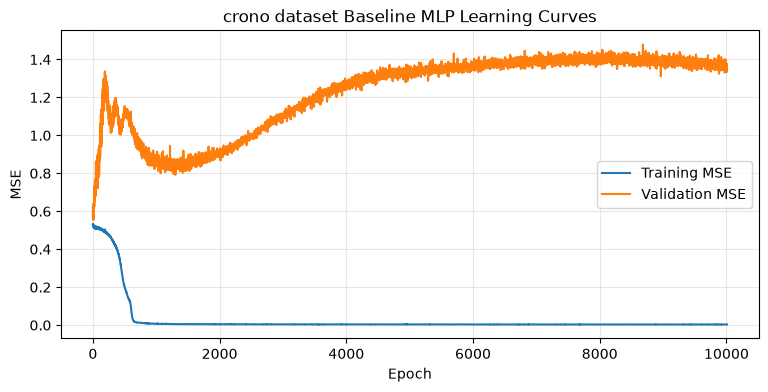

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.plot(history["train_loss"], label="Training MSE")
plt.plot(history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("crono dataset Baseline MLP Learning Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import torch

def plot_predictions(model, preprocessor, x_min=-10*np.pi, x_max=10*np.pi):
    x = np.linspace(x_min, x_max, 2000)
    x_scaled = preprocessor.transform(x)

    model.eval()
    with torch.inference_mode():
        x_tensor = torch.from_numpy(x_scaled)
        y_pred = model(x_tensor).cpu().numpy().ravel()

    # Ground truth used for evaluation/visualization only.
    y_true = np.sin(x) + 0.3 * np.sin(3 * x)

    plt.figure(figsize=(12, 4))
    plt.plot(x, y_true, label="Ground truth")
    plt.plot(x, y_pred, "--", label="MLP prediction")
    plt.xlabel("x")
    plt.ylabel("f(x)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

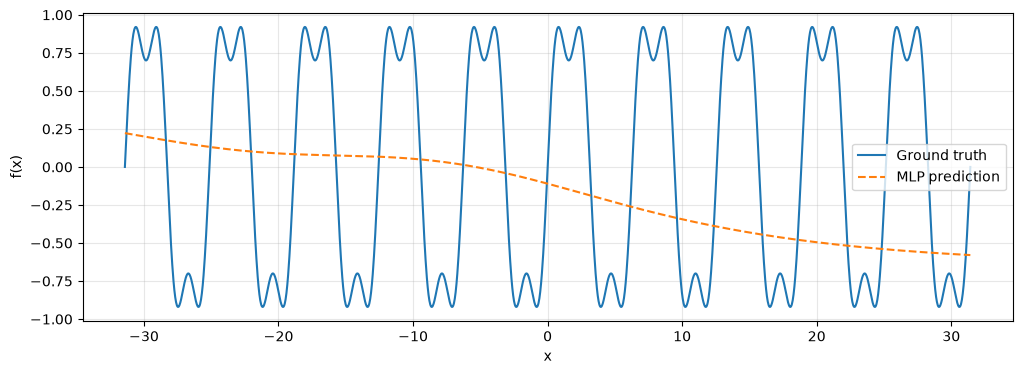

In [29]:
plot_predictions(model, chrono_preprocessor)

In [37]:
from function_approximation.training.config import load_experiment_config
from pathlib import Path
print(Path.cwd())
config = load_experiment_config("../configs/mlp_chrono.yaml")

print("Experiment:", config["experiment"]["run_name"])
print("Model:", config["model"]["type"])
print("Split:", config["data"]["split_strategy"])
print("Learning rate:", config["training"]["learning_rate"])

/Volumes/Ankit's SSD 1/MyProject/Andromeda-TakeHome/notebook
Experiment: mlp_chronological_standard_seed42
Model: mlp
Split: chronological
Learning rate: 0.001
